# Forecasting with Moirai

In [1]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from gluonts.dataset.pandas import PandasDataset
from gluonts.dataset.split import split

from uni2ts.model.moirai import MoiraiForecast, MoiraiModule

import warnings

warnings.filterwarnings("ignore")

/Users/davidhuang/Documents/GitHub/time-series/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
plt.rcParams["font.size"] = 14
plt.rcParams["axes.labelsize"] = 14
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["xtick.labelsize"] = 14
plt.rcParams["ytick.labelsize"] = 14
plt.rcParams["legend.fontsize"] = 14
plt.rcParams["lines.linewidth"] = 2
plt.rcParams["axes.prop_cycle"] = plt.cycler(
    color=[
        "#000072",  # blue (for historical data)
        "#80c21d",  # green (for actual data)
        "#924eae",  # purple
        "#ff0000",  # red
        "#ff9100",  # orange
    ]
)

## Zero-shot forecasting with Moirai

In [3]:
df = pd.read_csv("../data/walmart_sales_small.csv", parse_dates=["Date"])

df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106


In [ ]:
df = df[["Store", "Date", "Weekly_Sales"]]
df = df.set_index("Date")
df.head()

,Store,Weekly_Sales
Date,,
2010-02-05,1,1643690.90
2010-02-12,1,1641957.44
2010-02-19,1,1611968.17
2010-02-26,1,1409727.59
2010-03-05,1,1554806.68


In [5]:
ds = PandasDataset.from_long_dataframe(df, target="Weekly_Sales", item_id="Store")

In [6]:
model = MoiraiForecast(
    module=MoiraiModule.from_pretrained("Salesforce/moirai-1.0-R-small"),
    prediction_length=8,
    context_length=len(df.query("Store == 1")),
    patch_size="auto",
    num_samples=100,
    target_dim=1,
    feat_dynamic_real_dim=ds.num_feat_dynamic_real,
    past_feat_dynamic_real_dim=ds.num_past_feat_dynamic_real,
)

In [7]:
predictor = model.create_predictor(batch_size=32)
forecasts = predictor.predict(ds)
forecasts = list(forecasts)

In [8]:
def get_median_and_ci(data, start_date, horizon, freq, id, confidence=0.95):

    n_samples, n_timesteps = data.shape

    # Calculate the median for each timestep
    medians = np.median(data, axis=0)

    # Calculate the lower and upper percentile for the given confidence interval
    lower_percentile = (1 - confidence) / 2 * 100
    upper_percentile = (1 + confidence) / 2 * 100

    # Calculate the lower and upper bounds for each timestep
    lower_bounds = np.percentile(data, lower_percentile, axis=0)
    upper_bounds = np.percentile(data, upper_percentile, axis=0)

    pred_dates = pd.date_range(start=start_date, periods=horizon, freq=freq)
    formatted_dates = pred_dates.strftime("%m-%d-%Y").tolist()

    # Create a DataFrame with the results
    df = pd.DataFrame(
        {
            "Date": formatted_dates,
            "Store": id,
            "Moirai": medians,
            f"Moirai-lo-{int(confidence*100)}": lower_bounds,
            f"Moirai-hi-{int(confidence*100)}": upper_bounds,
        }
    )

    return df

In [9]:
preds = [
    get_median_and_ci(
        data=forecasts[i].samples,
        start_date="11-02-2012",
        horizon=8,
        freq="W-FRI",
        id=i + 1,
    )
    for i in range(4)
]

preds_df = pd.concat(preds, axis=0, ignore_index=True)
preds_df["Date"] = pd.to_datetime(preds_df["Date"])

preds_df.head()

,Date,Store,Moirai,Moirai-lo-95,Moirai-hi-95
0,2012-11-02,1,1525813.500,1.402899e+06,1.700062e+06
1,2012-11-09,1,1530077.875,1.201752e+06,1.728505e+06
2,2012-11-16,1,1536645.625,1.260750e+06,1.903028e+06
3,2012-11-23,1,1540919.250,1.262502e+06,1.826849e+06
4,2012-11-30,1,1530097.750,1.302524e+06,1.800044e+06


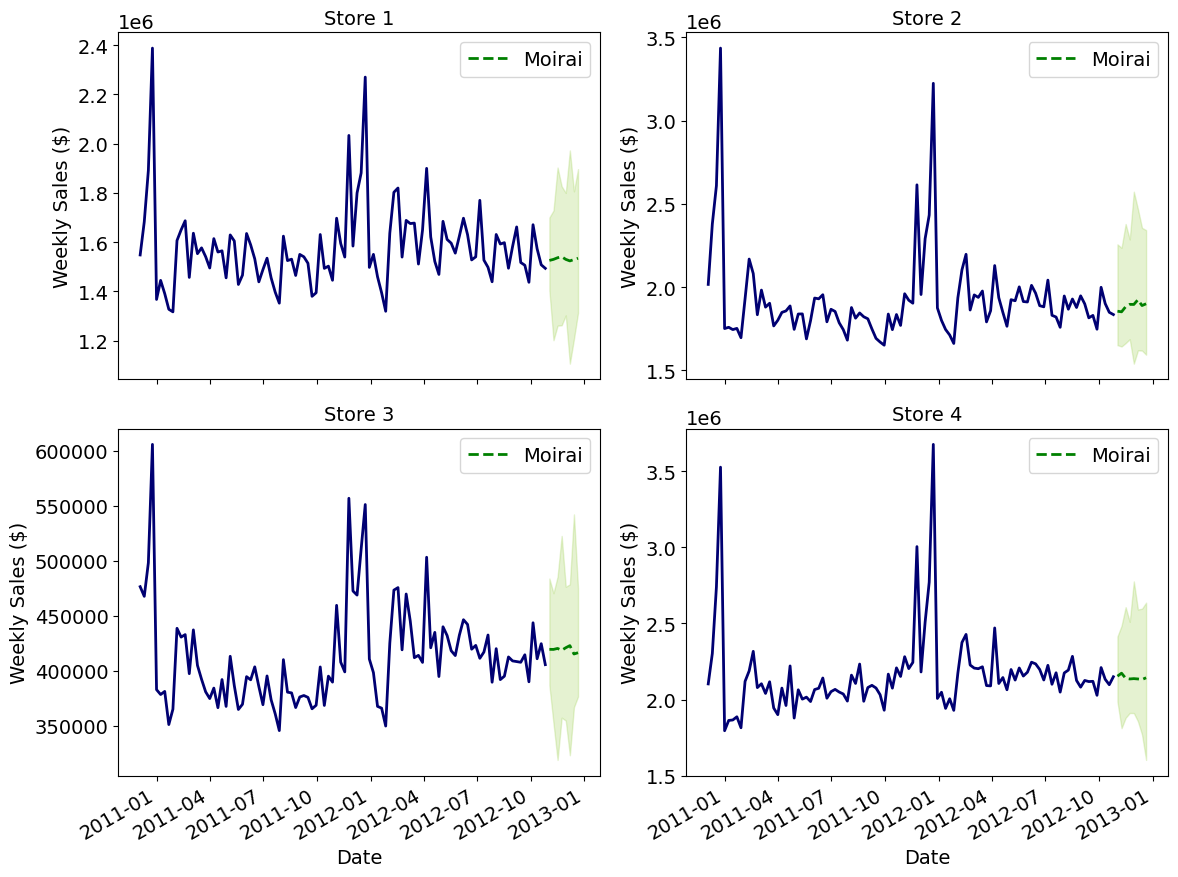

In [10]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 9))

plot_df = df.reset_index(drop=False).copy()
plot_preds_df = preds_df.copy()

for i, ax in enumerate(axes.flatten()):
    df = plot_df[plot_df["Store"] == i + 1].iloc[-100:]
    preds_df = plot_preds_df[plot_preds_df["Store"] == i + 1]

    ax.plot(df["Date"], df["Weekly_Sales"])
    ax.plot(preds_df["Date"], preds_df["Moirai"], "g--", label="Moirai")
    ax.fill_between(
        preds_df["Date"],
        preds_df["Moirai-lo-95"],
        preds_df["Moirai-hi-95"],
        alpha=0.2,
        color="#80c21d",
    )
    ax.legend()
    ax.set_title(f"Store {i+1}")
    ax.set_xlabel("Date")
    ax.set_ylabel("Weekly Sales ($)")

fig.autofmt_xdate()
plt.tight_layout()

## Cross-validation with Moirai

In [ ]:
df = pd.read_csv("../data/walmart_sales_small.csv", parse_dates=["Date"])
df = df.query("Store == 1")
df = df[["Store", "Date", "Weekly_Sales"]]
df = df.set_index("Date")

df.head()

,Store,Weekly_Sales
Date,,
2010-02-05,1,1643690.90
2010-02-12,1,1641957.44
2010-02-19,1,1611968.17
2010-02-26,1,1409727.59
2010-03-05,1,1554806.68


In [12]:
ds = PandasDataset.from_long_dataframe(df, target="Weekly_Sales", item_id="Store")

In [13]:
train, test_template = split(ds, offset=-32)

test_data = test_template.generate_instances(prediction_length=8, windows=4, distance=8)

In [14]:
model = MoiraiForecast(
    module=MoiraiModule.from_pretrained(f"Salesforce/moirai-1.0-R-small"),
    prediction_length=8,
    context_length=100,
    patch_size="auto",
    num_samples=100,
    target_dim=1,
    feat_dynamic_real_dim=ds.num_feat_dynamic_real,
    past_feat_dynamic_real_dim=ds.num_past_feat_dynamic_real,
)

predictor = model.create_predictor(batch_size=32)
forecasts = predictor.predict(test_data.input)

forecasts = list(forecasts)

In [15]:
start_dates = ["2012-03-23", "2012-05-18", "2012-07-13", "2012-09-07"]

cv_preds = [
    get_median_and_ci(
        data=forecasts[i].samples,
        start_date=start_dates[i],
        horizon=8,
        freq="W-FRI",
        id=1,
    )
    for i in range(4)
]

cv_preds_df = pd.concat(cv_preds, axis=0, ignore_index=True)
cv_preds_df["Date"] = pd.to_datetime(cv_preds_df["Date"])

cv_preds_df.head()

,Date,Store,Moirai,Moirai-lo-95,Moirai-hi-95
0,2012-03-23,1,1632043.375,1.429706e+06,2.228659e+06
1,2012-03-30,1,1638072.000,1.335027e+06,3.027196e+06
2,2012-04-06,1,1632419.500,1.408608e+06,2.420676e+06
3,2012-04-13,1,1578791.500,1.335233e+06,2.016732e+06
4,2012-04-20,1,1579107.625,1.362956e+06,1.986936e+06


In [16]:
cv_preds_df["Weekly_Sales"] = df.iloc[-32:]["Weekly_Sales"].values
cv_preds_df.head()

,Date,Store,Moirai,Moirai-lo-95,Moirai-hi-95,Weekly_Sales
0,2012-03-23,1,1632043.375,1.429706e+06,2.228659e+06,1511068.07
1,2012-03-30,1,1638072.000,1.335027e+06,3.027196e+06,1649604.63
2,2012-04-06,1,1632419.500,1.408608e+06,2.420676e+06,1899676.88
3,2012-04-13,1,1578791.500,1.335233e+06,2.016732e+06,1621031.70
4,2012-04-20,1,1579107.625,1.362956e+06,1.986936e+06,1521577.87


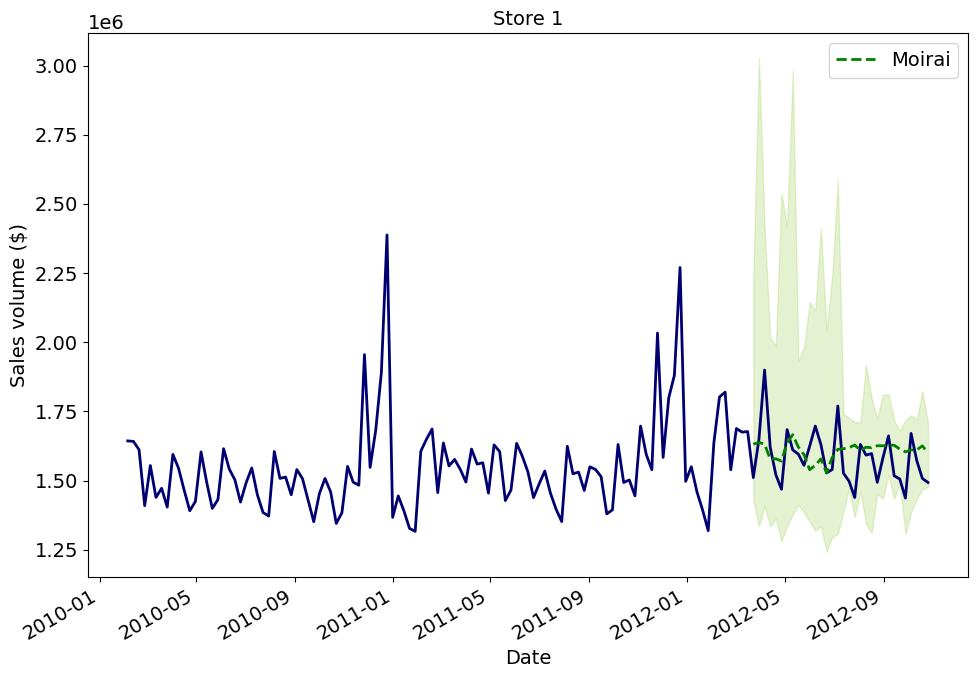

In [17]:
fig, ax = plt.subplots(figsize=(10, 7))

plot_df = df.reset_index(drop=False).copy()

ax.plot(plot_df["Date"], plot_df["Weekly_Sales"])
ax.plot(
    cv_preds_df["Date"], cv_preds_df["Moirai"], ls="--", color="green", label="Moirai"
)
ax.fill_between(
    cv_preds_df["Date"],
    cv_preds_df["Moirai-lo-95"],
    cv_preds_df["Moirai-hi-95"],
    color="#80c21d",
    alpha=0.2,
)

ax.set_title(f"Store 1")
ax.set_xlabel("Date")
ax.set_ylabel("Sales volume ($)")
ax.legend(loc=1)

fig.autofmt_xdate()
plt.tight_layout()

In [18]:
from utilsforecast.losses import mae, smape
from utilsforecast.evaluation import evaluate

evaluation = evaluate(
    cv_preds_df,
    metrics=[mae, smape],
    models=["Moirai"],
    target_col="Weekly_Sales",
    id_col="Store",
)

evaluation

,Store,metric,Moirai
0,1,mae,82386.463750
1,1,smape,0.025801


## Forecasting with features

In [19]:
df = pd.read_csv("../data/walmart_sales_small.csv", parse_dates=["Date"])
df = df.query("Store == 1")
df = df.set_index("Date")

df.head()

,Store,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
Date,,,,,,,
2010-02-05,1,1643690.90,0,42.31,2.572,211.096358,8.106
2010-02-12,1,1641957.44,1,38.51,2.548,211.242170,8.106
2010-02-19,1,1611968.17,0,39.93,2.514,211.289143,8.106
2010-02-26,1,1409727.59,0,46.63,2.561,211.319643,8.106
2010-03-05,1,1554806.68,0,46.50,2.625,211.350143,8.106


In [20]:
ds = PandasDataset.from_long_dataframe(
    df,
    target="Weekly_Sales",
    item_id="Store",
    past_feat_dynamic_real=["Temperature", "Fuel_Price", "CPI", "Unemployment"],
    feat_dynamic_real=["Holiday_Flag"],
)

In [21]:
train, test_template = split(ds, offset=-32)

test_data = test_template.generate_instances(prediction_length=8, windows=4, distance=8)

In [22]:
model = MoiraiForecast(
    module=MoiraiModule.from_pretrained(f"Salesforce/moirai-1.0-R-small"),
    prediction_length=8,
    context_length=100,
    patch_size="auto",
    num_samples=100,
    target_dim=1,
    feat_dynamic_real_dim=ds.num_feat_dynamic_real,
    past_feat_dynamic_real_dim=ds.num_past_feat_dynamic_real,
)

predictor = model.create_predictor(batch_size=32)
forecasts = predictor.predict(test_data.input)
forecasts = list(forecasts)

In [ ]:
start_dates = ["2012-03-23", "2012-05-18", "2012-07-13", "2012-09-07"]

cv_feat_preds = [
    get_median_and_ci(
        data=forecasts[i].samples,
        start_date=start_dates[i],
        horizon=8,
        freq="W-FRI",
        id=1,
    )
    for i in range(4)
]

cv_feat_preds_df = pd.concat(cv_feat_preds, axis=0, ignore_index=True)
cv_feat_preds_df["Date"] = pd.to_datetime(cv_feat_preds_df["Date"])

cv_feat_preds_df["Weekly_Sales"] = df.iloc[-32:]["Weekly_Sales"].values
cv_feat_preds_df.head()

,Date,Store,Moirai,Moirai-lo-95,Moirai-hi-95,Weekly_Sales
0,2012-03-23,1,1693737.375,1.410470e+06,2.370012e+06,1511068.07
1,2012-03-30,1,1653183.750,1.395255e+06,2.572935e+06,1649604.63
2,2012-04-06,1,1629197.000,1.373196e+06,2.568040e+06,1899676.88
3,2012-04-13,1,1603154.750,1.213401e+06,2.320336e+06,1621031.70
4,2012-04-20,1,1625076.125,1.369393e+06,2.410303e+06,1521577.87


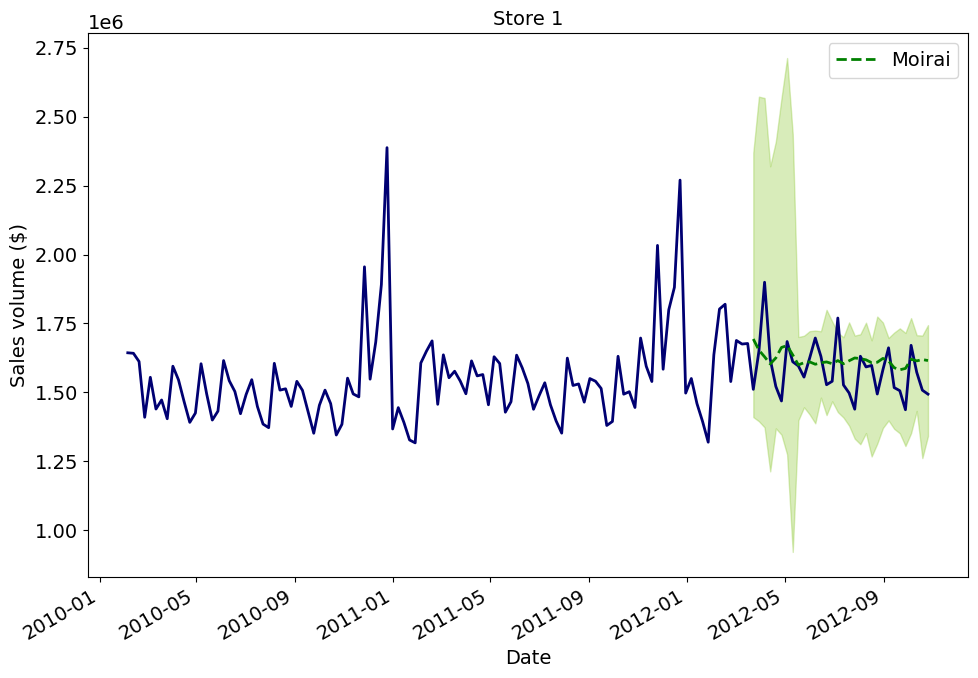

In [24]:
fig, ax = plt.subplots(figsize=(10, 7))

plot_df = df.reset_index(drop=False).copy()

ax.plot(plot_df["Date"], plot_df["Weekly_Sales"])
ax.plot(
    cv_feat_preds_df["Date"],
    cv_feat_preds_df["Moirai"],
    ls="--",
    color="green",
    label="Moirai",
)
ax.fill_between(
    cv_feat_preds_df["Date"],
    cv_feat_preds_df["Moirai-lo-95"],
    cv_feat_preds_df["Moirai-hi-95"],
    color="#80c21d",
    alpha=0.3,
)

ax.set_title(f"Store 1")
ax.set_xlabel("Date")
ax.set_ylabel("Sales volume ($)")
ax.legend(loc=1)

fig.autofmt_xdate()
plt.tight_layout()

In [25]:
evaluation = evaluate(
    cv_feat_preds_df,
    metrics=[mae, smape],
    models=["Moirai"],
    target_col="Weekly_Sales",
    id_col="Store",
)

evaluation

,Store,metric,Moirai
0,1,mae,79730.420469
1,1,smape,0.024962


## Anomaly detection

In [26]:
df = pd.read_csv("../data/nyc_taxi_anomaly_daily.csv", parse_dates=["timestamp"])
df.head()

,timestamp,value,is_anomaly
0,2014-07-01,745967,0
1,2014-07-02,733640,0
2,2014-07-03,710142,0
3,2014-07-04,552565,0
4,2014-07-05,555470,0


In [27]:
def anomaly_detection_moirai(
    df, target_col, id_col, date_col, h, n_windows, freq, confidence=0.99
):

    ds = PandasDataset.from_long_dataframe(
        df,
        target=target_col,
        item_id=id_col,
    )

    train, test_template = split(ds, offset=-(n_windows * h))

    test_data = test_template.generate_instances(
        prediction_length=h, windows=n_windows, distance=h
    )

    model = MoiraiForecast(
        module=MoiraiModule.from_pretrained(f"Salesforce/moirai-1.0-R-small"),
        prediction_length=h,
        context_length=100,
        patch_size="auto",
        num_samples=100,
        target_dim=1,
        feat_dynamic_real_dim=ds.num_feat_dynamic_real,
        past_feat_dynamic_real_dim=ds.num_past_feat_dynamic_real,
    )

    predictor = model.create_predictor(batch_size=32)
    forecasts = predictor.predict(test_data.input)
    forecasts = list(forecasts)

    df_test = df[-(n_windows * h) :]

    list_dates = df_test[date_col]
    start_dates = list(list_dates[::h])

    cv_preds = [
        get_median_and_ci(
            data=forecasts[i].samples,
            start_date=start_dates[i],
            horizon=h,
            freq=freq,
            id=0,
            confidence=confidence,
        )
        for i in range(n_windows)
    ]

    cv_preds_df = pd.concat(cv_preds, axis=0, ignore_index=True)
    cv_preds_df["Date"] = pd.to_datetime(cv_preds_df["Date"])

    df_test.rename(columns={date_col: "Date"}, inplace=True)
    df_test = pd.merge(df_test, cv_preds_df, on="Date")
    df_test["anomaly"] = (
        (df_test[target_col] < df_test["Moirai-lo-99"])
        | (df_test[target_col] > df_test["Moirai-hi-99"])
    ).astype(int)

    df_test = df_test.drop("Store", axis=1)

    return df_test

In [28]:
df["unique_id"] = 0

anomaly_df = anomaly_detection_moirai(
    df,
    target_col="value",
    id_col="unique_id",
    date_col="timestamp",
    h=23,
    n_windows=8,
    freq="D",
    confidence=0.99,
)
anomaly_df.head()

,Date,value,is_anomaly,unique_id,Moirai,Moirai-lo-99,Moirai-hi-99,anomaly
0,2014-08-01,769160,0,0,721670.8750,624741.740938,1.523679e+06,0
1,2014-08-02,781616,0,0,722550.8750,660254.762813,1.972748e+06,0
2,2014-08-03,699449,0,0,749029.9375,645808.766250,1.143797e+06,0
3,2014-08-04,662215,0,0,717592.8125,627091.489688,9.765562e+06,0
4,2014-08-05,710728,0,0,726982.8750,651107.725625,2.503214e+06,0


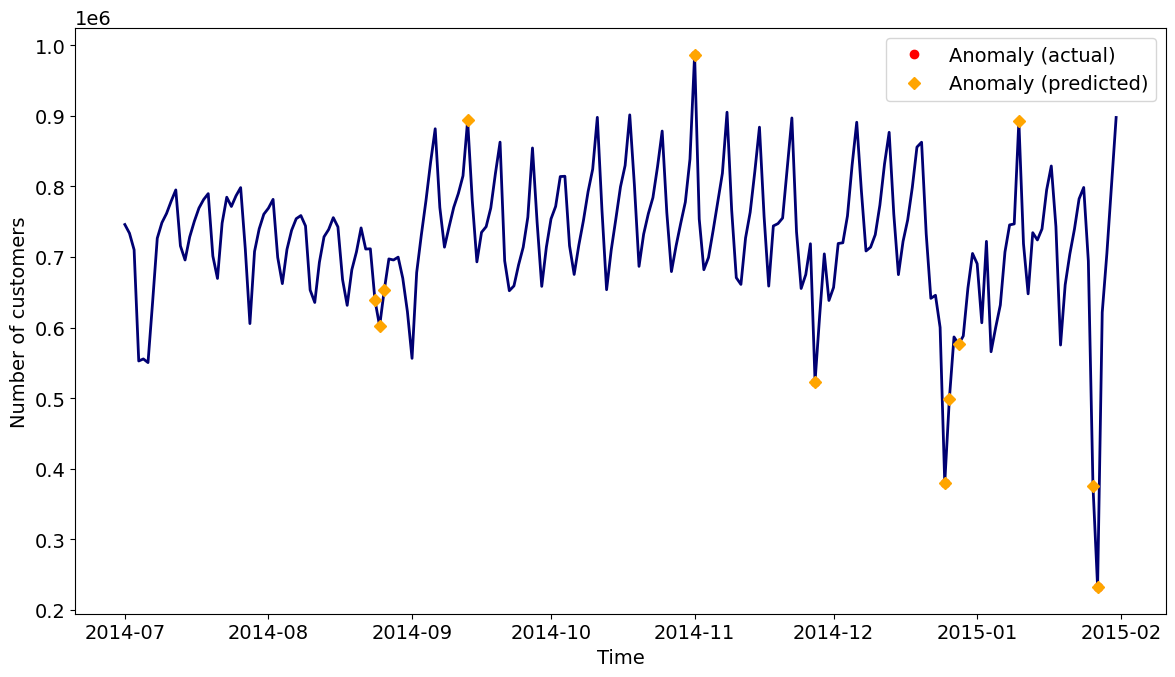

In [29]:
actual_anomaly_df = df.loc[df["is_anomaly"] == 1]
pred_anomaly_df = anomaly_df.loc[anomaly_df["anomaly"] == 1]

fig, ax = plt.subplots(figsize=(12, 7))

ax.plot(df["timestamp"], df["value"])
ax.plot(
    actual_anomaly_df["timestamp"],
    actual_anomaly_df["value"],
    "o",
    color="red",
    label="Anomaly (actual)",
)
ax.plot(
    pred_anomaly_df["Date"],
    pred_anomaly_df["value"],
    "D",
    color="orange",
    label="Anomaly (predicted)",
)
ax.set_xlabel("Time")
ax.set_ylabel("Number of customers")
ax.legend(loc="best")

plt.tight_layout()

In [ ]:
def evaluate_anomaly_detection(df, preds_col, actual_col):
    tp = ((df[preds_col] == 1) & (df[actual_col] == 1)).sum()
    tn = ((df[preds_col] == 0) & (df[actual_col] == 0)).sum()
    fp = ((df[preds_col] == 1) & (df[actual_col] == 0)).sum()
    fn = ((df[preds_col] == 0) & (df[actual_col] == 1)).sum()
    precision = tp / (tp + fp) if (tp + fp) != 0 else 0
    recall = tp / (tp + fn) if (tp + fn) != 0 else 0
    f1_score = (
        2 * (precision * recall) / (precision + recall)
        if (precision + recall) != 0
        else 0
    )

    return precision, recall, f1_score

In [31]:
precision, recall, f1_score = evaluate_anomaly_detection(
    anomaly_df[-182:], "anomaly", "is_anomaly"
)

print(f"Precision: {round(precision,2)}")
print(f"Recall: {round(recall,2)}")
print(f"F1-Score: {round(f1_score,2)}")

Precision: 0.33
Recall: 1.0
F1-Score: 0.5
